---

<table style="width:100%">
  <tr>
    <th>
        <div style="text-align: center; background-color: #f0f0f0; padding: 20px; border-radius: 10px;">
<p style="text-align: center;"> Конспект лекцій з предмету: </p>
<p style="text-align: center;"><b><h2>"Схемотехніка радіотехнічних пристроїв. Частина 2"</h2></b></p>
<p style="text-align: center;"><b><h3>Тема 7. Операційні підсилювачі. Основні схеми включення</h3></b></p>
<p style="text-align: center;"> Національний університет "Чернігівська політехніка"</p>
<hr/>
<p style="text-align: center;"><b>Питання теми:</b></p>
<ul style="text-align: left;">
  <li>2.7. Основні параметри і схеми включення операційних підсилювачів</li>
  <li>2.8. Повторювачі напруги на операційних підсилювачах: приклади реалізації, основні параметри і області застосування</li>
  <li>2.9. Суматори сигналів на операційних підсилювачах: приклади реалізації, призначення та розрахункові співвідношення</li>
</ul>
</div>
    </th>
    <th>
<div style="text-align: center; background-color: #f0f0f0; padding: 20px; border-radius: 10px;">
<p style="text-align: center;"> <b>Викладач:</b> </p>
<p style="text-align: center;"> Доктор філософії</p>
<p style="text-align: center;"> Пахалюк Богдан Петрович</p>
<hr/>
<p style="text-align: center; font-size: 0.9em;">Тема 7 з 14</p>
</div>
    </th>
  </tr>
</table>

---


---

<p style="text-align: center;"><b>Зміст</b></p>

* [Операційний підсилювач: будова, параметри, схеми включення](#opamp-basics)
    * [🔬 Інтерактивно: АЧХ μA741 без ЗЗ і з ЗЗ: сталий добуток підсилення × смуга (PySpice)](#gbw-interactive)
    * [🔬 Інтерактивно: інвертувальний і неінвертувальний підсилювачі: насичення і швидкість наростання (PySpice)](#inv-interactive)
* [Повторювачі напруги на ОП](#followers)
    * [🔬 Інтерактивно: навіщо потрібен повторювач: навантаження подільника і двотактний вихід (PySpice)](#follower-interactive)
* [Суматори сигналів на ОП](#summers)
    * [🔬 Інтерактивно: інвертувальний і алгебраїчний суматори (PySpice)](#summer-interactive)
* [📌 Підсумок теми](#topic-summary)
* [📚 Рекомендована література та ресурси](#references)

> 💡 Код демонстрацій та інтерактивних графіків **згорнуто**, щоб не відволікати від матеріалу. Щоб переглянути його, натисніть на «⋯» (або на смужку ліворуч від комірки). Для роботи інтерактивних елементів виконайте всі комірки: *Run → Run All Cells*.

---

**Підключення бібліотек.** NumPy/SciPy/Matplotlib — чисельні розрахунки та графіки, SymPy — символьні обчислення, ipywidgets — інтерактивні повзунки, PySpice + ngspice — моделювання схем (ОП μA741, таймер 555 та транзистори описано SPICE-моделями з теки `spice/`), schemdraw — побудова схем з умовними позначеннями за ДСТУ. Цю комірку потрібно виконати першою; у Google Colab вона спершу встановлює ngspice і бібліотеки (близько хвилини).

In [1]:
import sys, os
if 'google.colab' in sys.modules and not os.path.exists('/usr/lib/x86_64-linux-gnu/libngspice.so'):   # Google Colab: ngspice та бібліотеки (~1 хв)
    !apt-get -qq install -y ngspice libngspice0-dev > /dev/null
    %pip install -q PySpice==1.5 schemdraw==0.23 engineering_notation==0.13.3

# SPICE-моделі компонентів (ОП μA741, таймер 555, діоди, транзистори) лежать у теці spice/;
# якщо зошит відкрито окремо (напр. у Colab), завантажуємо їх із репозиторію
SPICE_DIR = 'spice'
if not os.path.isdir(SPICE_DIR):
    import urllib.request
    os.makedirs(SPICE_DIR, exist_ok=True)
    _repo = 'https://raw.githubusercontent.com/vim4all/Lectures_Schematics_of_radio_technical-devices_in_Ukrainian/main/spice/'
    for _f in ['uA741.lib', 'BIP-555.lib', '1N4007.mod', '2n2222a.lib', '2n3904.lib']:
        urllib.request.urlretrieve(_repo + _f, os.path.join(SPICE_DIR, _f))
def spice_model(name):
    return os.path.abspath(os.path.join(SPICE_DIR, name))

import warnings
warnings.filterwarnings('ignore', message='Unable to import Axes3D')
import sympy as smp
from sympy import symbols, Matrix, simplify, factor, solve, Eq, latex
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal
from ipywidgets import interact, interactive, fixed, HBox, VBox, Output
import ipywidgets as widgets
from IPython.display import display, HTML, Markdown
%matplotlib inline
try:                                     # схеми й графіки — лише PNG (менший розмір зошитів)
    get_ipython().display_formatter.formatters['image/svg+xml'].enabled = False
except Exception:
    pass

import math
from engineering_notation import EngNumber

import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging(logging_level='ERROR')
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

# ngspice ≥ 41 пише в stderr інформаційні повідомлення (напр. "Using SPARSE 1.3 as Direct Linear Solver"),
# які PySpice 1.5 вважає помилкою симуляції. Сприймаємо як помилку лише рядки, що містять "error".
from PySpice.Spice.NgSpice import Shared as _ngspice_shared
_orig_send_char = _ngspice_shared.NgSpiceShared._send_char
def _send_char(message_c, ngspice_id, user_data):
    message = _ngspice_shared.ffi_string_utf8(message_c)
    prefix, _, content = message.partition(' ')
    if prefix == 'stderr' and 'error' not in content.lower() and 'init file' not in content:
        self = _ngspice_shared.ffi.from_handle(user_data)
        self._stderr.append(content)
        return self.send_char(message, ngspice_id)
    return _orig_send_char(message_c, ngspice_id, user_data)
_ngspice_shared.NgSpiceShared._send_char = staticmethod(_send_char)

def opamp_circuit(title, supply=15):
    """Схема з ОП μA741 і двополярним живленням ±supply (вузли vcc, vee)."""
    c = Circuit(title)
    c.include(spice_model('uA741.lib'))
    c.V('cc', 'vcc', c.gnd, supply)
    c.V('ee', 'vee', c.gnd, -supply)
    return c

def add_opamp(c, name, plus, minus, out):
    """ОП μA741: X<name> (+) (−) Vcc Vee вихід."""
    c.X(name, 'UA741', plus, minus, 'vcc', 'vee', out)

def tran(c, step, stop, start=0, **kw):
    """Перехідний аналіз: повертає (t, словник напруг вузлів у вигляді numpy-масивів)."""
    a = c.simulator(temperature=25, nominal_temperature=25).transient(step_time=step, end_time=stop, start_time=start, **kw)
    return np.array(a.time), {str(k): np.array(v) for k, v in a.nodes.items()}

def ac(c, f_start=1, f_stop=10e6, points=40):
    """AC-аналіз: повертає (f, словник комплексних напруг вузлів)."""
    a = c.simulator(temperature=25, nominal_temperature=25).ac(start_frequency=f_start, stop_frequency=f_stop,
                                                                 number_of_points=points, variation='dec')
    return np.array(a.frequency), {str(k): np.array(v) for k, v in a.nodes.items()}

def db(x):
    return 20 * np.log10(np.maximum(np.abs(x), 1e-12))

try:
    import schemdraw
    import schemdraw.elements as elm
    SCHEMDRAW_AVAILABLE = True
except ImportError:
    SCHEMDRAW_AVAILABLE = False
    print('schemdraw не встановлено (pip install schemdraw)')

plt.rcParams.update({
    'figure.figsize': (8, 4), 'axes.grid': True, 'grid.alpha': 0.3,
    'axes.labelsize': 12, 'axes.titlesize': 13, 'lines.linewidth': 2,
    'font.size': 11,
})

if SCHEMDRAW_AVAILABLE:
    # Умовні позначення за ДСТУ/IEC: резистор — прямокутник, джерело ЕРС — коло зі стрілкою,
    # операційний підсилювач — прямокутник із символом ▷∞, логічні елементи — прямокутники з «&», «1»
    from schemdraw.segments import Segment, SegmentCircle, SegmentText
    elm.style(elm.STYLE_IEC)
    schemdraw.use('matplotlib')
    import schemdraw.backends.svgtext as _svgtext       # оцінювач розміру тексту schemdraw не сприймає символ «&»
    _orig_text_size = _svgtext.text_approx_size
    _svgtext.text_approx_size = lambda text, *a, **k: _orig_text_size(text.replace('&', '8'), *a, **k)

    class EMF(elm.Source):
        """Джерело ЕРС: стрілка всередині кола вказує напрямок дії ЕРС."""
        def __init__(self, **kwargs):
            super().__init__(**kwargs)
            self.segments.append(Segment([(.2, 0), (.8, 0)], arrow='->', arrowwidth=.16, arrowlength=.25))

    class CurrentSource(elm.Source):
        """Джерело струму: подвійна стрілка вказує напрямок струму."""
        def __init__(self, **kwargs):
            super().__init__(**kwargs)
            self.segments.append(Segment([(.15, 0), (.85, 0)], arrow='->', arrowwidth=.16, arrowlength=.2))
            self.segments.append(Segment([(.15, 0), (.62, 0)], arrow='->', arrowwidth=.16, arrowlength=.2))

    class OpAmp(elm.Element):
        """Операційний підсилювач за ДСТУ: прямокутник із символом ▷∞.
        Інвертувальний вхід in1 (з кружечком інверсії) — угорі, неінвертувальний in2 — унизу;
        swap=True міняє входи місцями (неінвертувальний — угорі). Виводи: in1, in2, out, vd (живлення +), vs (живлення −)."""
        def __init__(self, swap=False, signs=True, **kwargs):
            super().__init__(**kwargs)
            w, h, lead, r = 2.0, 2.6, 0.6, 0.12
            yi, yn = (0.65, -0.65) if not swap else (-0.65, 0.65)
            self.segments.append(Segment([(0, h/2), (w, h/2), (w, -h/2), (0, -h/2), (0, h/2)]))
            self.segments.append(Segment([(0.55, h/2 - 0.3), (0.55, h/2 - 0.8), (0.95, h/2 - 0.55), (0.55, h/2 - 0.3)]))
            self.segments.append(SegmentText((1.35, h/2 - 0.55), '∞', fontsize=14))
            self.segments.append(SegmentCircle((-r, yi), r))
            self.segments.append(Segment([(-lead, yi), (-2*r, yi)]))
            self.segments.append(Segment([(-lead, yn), (0, yn)]))
            self.segments.append(Segment([(w, 0), (w + lead, 0)]))
            if signs:
                self.segments.append(SegmentText((0.25, yi), '−', fontsize=12))
                self.segments.append(SegmentText((0.25, yn), '+', fontsize=12))
            self.anchors.update({'in1': (-lead, yi), 'in2': (-lead, yn), 'out': (w + lead, 0),
                                 'vd': (w/2, h/2), 'vs': (w/2, -h/2), 'center': (w/2, 0)})
            self.elmparams['drop'] = (w + lead, 0)
            self.theta(0)            # не успадковувати напрямок попереднього елемента

    class Gate(elm.Element):
        """Логічний елемент за ДСТУ: прямокутник із функцією ('&', '1', '=1') і кружечком інверсії на виході.
        Виводи: in1 … inN (зверху вниз), out."""
        def __init__(self, func='&', inputs=2, inv=True, **kwargs):
            super().__init__(**kwargs)
            w, lead, r = 1.4, 0.5, 0.12
            h = max(1.4, 0.8 * inputs)
            self.segments.append(Segment([(0, h/2), (w, h/2), (w, -h/2), (0, -h/2), (0, h/2)]))
            self.segments.append(SegmentText((w/2, h/2 - 0.3), func, fontsize=13))
            ys = [0.0] if inputs == 1 else list(np.linspace(h/2 - 0.4, -h/2 + 0.4, inputs))
            for k, y in enumerate(ys):
                self.segments.append(Segment([(-lead, y), (0, y)]))
                self.anchors[f'in{k+1}'] = (-lead, y)
            x0 = w
            if inv:
                self.segments.append(SegmentCircle((w + r, 0), r))
                x0 = w + 2*r
            self.segments.append(Segment([(x0, 0), (w + lead, 0)]))
            self.anchors.update({'out': (w + lead, 0), 'center': (w/2, 0)})
            self.elmparams['drop'] = (w + lead, 0)
            self.theta(0)            # не успадковувати напрямок попереднього елемента

---

## Операційний підсилювач: будова, параметри, схеми включення <a class="anchor" id="opamp-basics"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 2.7</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Пояснювати внутрішню структуру ОП і призначення його каскадів
> - Знати основні параметри ОП та їхні типові значення
> - Застосовувати правила ідеального ОП для аналізу схем з НЗЗ
> - Розраховувати інвертувальний, неінвертувальний і диференціальний підсилювачі з урахуванням обмеженої смуги і швидкості наростання

</div>

**Операційний підсилювач (ОП)** — інтегральний підсилювач постійного струму з диференціальним входом, дуже великим коефіцієнтом підсилення, великим вхідним і малим вихідним опором. Назва походить від аналогових обчислювальних машин, де ОП з відповідними колами ЗЗ виконували математичні **операції**: додавання, віднімання, інтегрування, диференціювання, логарифмування. Сьогодні ОП — універсальний «будівельний блок» аналогової схемотехніки: властивості пристрою на ОП задаються **зовнішнім колом зворотного зв'язку**, а не параметрами транзисторів.

### Будова

Класичний ОП (μA741 і подібні) має три каскади, вивчені в темах 5–6:
1. **вхідний диференціальний каскад** (пари СК–СБ з дзеркальним активним навантаженням) — забезпечує диференціальний вхід, великий КПСС, малі вхідні струми;
2. **проміжний каскад підсилення напруги** (двійка СК–СЕ з активним навантаженням) з **коригувальним конденсатором** $C_к$ ≈ 30 пФ (корекція «назад», домінантний полюс, тема 2);
3. **вихідний двотактний повторювач** класу AB — малий вихідний опір, захист від короткого замикання.

**Умовне позначення.** За ДСТУ (ГОСТ 2.759) ОП зображують прямокутником зі знаком підсилення ▷ і символом ∞ (дуже велике підсилення); інвертувальний вхід позначають кружечком (у конспекті додатково — знаком «−»). У зарубіжній літературі поширене зображення трикутником.

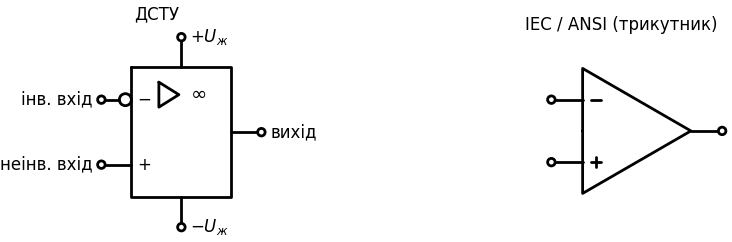

In [2]:
# Умовні позначення ОП: за ДСТУ (прямокутник) і в зарубіжній літературі (трикутник)
if SCHEMDRAW_AVAILABLE:
    with schemdraw.Drawing(fontsize=12, unit=2) as d:
        d += (o1 := OpAmp().at((0, 0)).anchor('in1'))
        d += elm.Label().at((1.0, 1.6)).label('ДСТУ')
        d += elm.Dot(open=True).at(o1.in1).label('інв. вхід', loc='left'); d += elm.Dot(open=True).at(o1.in2).label('неінв. вхід', loc='left')
        d += elm.Dot(open=True).at(o1.out).label('вихід', loc='right')
        d += elm.Line().at(o1.vd).up(0.6); d += elm.Dot(open=True).label('$+U_ж$', loc='right')
        d += elm.Line().at(o1.vs).down(0.6); d += elm.Dot(open=True).label('$-U_ж$', loc='right')
        d += (o2 := elm.Opamp(leads=True).theta(0).at((9, 0)).anchor('in1'))
        d += elm.Label().at((10.3, 1.6)).label('IEC / ANSI (трикутник)')
        d += elm.Dot(open=True).at(o2.in1); d += elm.Dot(open=True).at(o2.in2); d += elm.Dot(open=True).at(o2.out)

### Основні параметри ОП

| Параметр | Позначення | Ідеальний ОП | μA741 | Сучасні ОП (приклади) |
|---|---|---|---|---|
| Коефіцієнт підсилення без ЗЗ | $K_0$ ($A_{OL}$) | ∞ | $2\cdot10^5$ (106 дБ) | $10^5\ldots10^7$ |
| Частота одиничного підсилення | $f_1$ (GBW) | ∞ | 1 МГц | 10 МГц (TL071 — 3 МГц, OPA2134 — 8 МГц), до ГГц |
| Швидкість наростання | $V_{U}$ (SR) | ∞ | 0,5 В/мкс | 13 В/мкс (TL071), 2000 В/мкс (THS3001) |
| Напруга зміщення нуля | $U_{зм}$ ($V_{OS}$) | 0 | 1…5 мВ | 10 мкВ (OP07), 1 мкВ (з автокоригуванням нуля) |
| Дрейф $U_{зм}$ | $dU_{зм}/dT$ | 0 | 15 мкВ/°C | 0,05…1 мкВ/°C |
| Вхідний струм | $I_{вх}$ | 0 | 80…500 нА | 20 пА (TL071 на ПТ), 3 фА (LMC6001) |
| Різниця вхідних струмів | $\Delta I_{вх}$ | 0 | 20 нА | — |
| Вхідний опір (диференціальний) | $R_{вх}$ | ∞ | 2 МОм | $10^{12}$ Ом (ПТ-вхід) |
| Вихідний опір (без ЗЗ) | $R_{вих}$ | 0 | 75 Ом | — |
| КПСС (CMRR) | | ∞ | 90 дБ | 100…140 дБ |
| Коефіцієнт впливу живлення (PSRR) | | ∞ | 90 дБ | 100…120 дБ |
| Максимальна вихідна напруга | $U_{вих.max}$ | $\pm U_ж$ | $\pm(U_ж - 2)$ В | rail-to-rail: до $\pm U_ж$ |
| Спектральна густина шуму | $e_ш$ | 0 | 20 нВ/√Гц | 1…5 нВ/√Гц (NE5534, AD797) |

**Частотна характеристика** скоригованого ОП — однополюсна: $K(jf) = \dfrac{K_0}{1 + jf/f_0}$, де $f_0 = f_1/K_0$ (для μA741 ≈ 5…10 Гц). Вище $f_0$ АЧХ спадає на 20 дБ/дек, і добуток **підсилення × смуга = $f_1$** — сталий (тема 2). Отже, підсилювач з $K_{зз} = 100$ на μA741 має смугу лише 10 кГц.

**Швидкість наростання (SR)** — максимальна швидкість зміни вихідної напруги, обмежена струмом, яким вхідний каскад перезаряджає $C_к$: $V_U = I_1/C_к$. Для синусоїди з амплітудою $U_m$ спотворень немає, якщо
$$2\pi f U_m \le V_U\quad\Rightarrow\quad f_{max} = \frac{V_U}{2\pi U_m}\;(\text{смуга повної потужності}).$$
Для μA741 при $U_m = 10$ В: $f_{max} \approx 8$ кГц.

### Правила аналізу схем з ідеальним ОП

Якщо ОП охоплено **негативним** ЗЗ і він не в насиченні:
1. **«Віртуальне коротке замикання»:** $U_+ \approx U_-$, бо $U_{вих}$ скінченна, а $K_0 \to \infty$: $U_+ - U_- = U_{вих}/K_0 \to 0$;
2. **вхідні струми дорівнюють нулю:** $I_+ = I_- = 0$.

Цих двох правил достатньо, щоб за законами Кірхгофа розрахувати будь-яку лінійну схему на ОП.

### Основні схеми включення

**Інвертувальний підсилювач** (паралельний НЗЗ за напругою). Неінвертувальний вхід заземлено, тож інвертувальний — «віртуальна земля» ($U_- = 0$). Струм $U_{вх}/R_1$ повністю тече через $R_2$:
$$K_u = -\frac{R_2}{R_1},\qquad R_{вх} = R_1,\qquad f_в = \frac{f_1}{1 + R_2/R_1}.$$

**Неінвертувальний підсилювач** (послідовний НЗЗ за напругою). $U_- = U_{вих}\dfrac{R_1}{R_1 + R_2} = U_{вх}$:
$$K_u = 1 + \frac{R_2}{R_1},\qquad R_{вх} \approx R_{вх.д}\frac{K_0}{K_u}\;(\text{сотні МОм – ГОм}),\qquad f_в = \frac{f_1}{K_u}.$$

**Диференціальний підсилювач (віднімач).** За принципом суперпозиції, при $R_3/R_4 = R_1/R_2$ (див. схему):
$$U_{вих} = \frac{R_2}{R_1}\,(U_{вх2} - U_{вх1}).$$
Недоліки — різні вхідні опори входів і залежність КПСС від точності резисторів (похибка 0,1 % дає КПСС ≈ 60 дБ); удосконалений варіант — вимірювальний підсилювач (тема 8).

**Компенсація вхідних струмів.** Вхідні струми $I_{вх}$, протікаючи через резистори, створюють похибку на виході. Якщо опори, «видимі» з обох входів, однакові — $R_3 = R_1\parallel R_2$ у колі неінвертувального входу, — похибка визначається лише різницею $\Delta I_{вх}$.

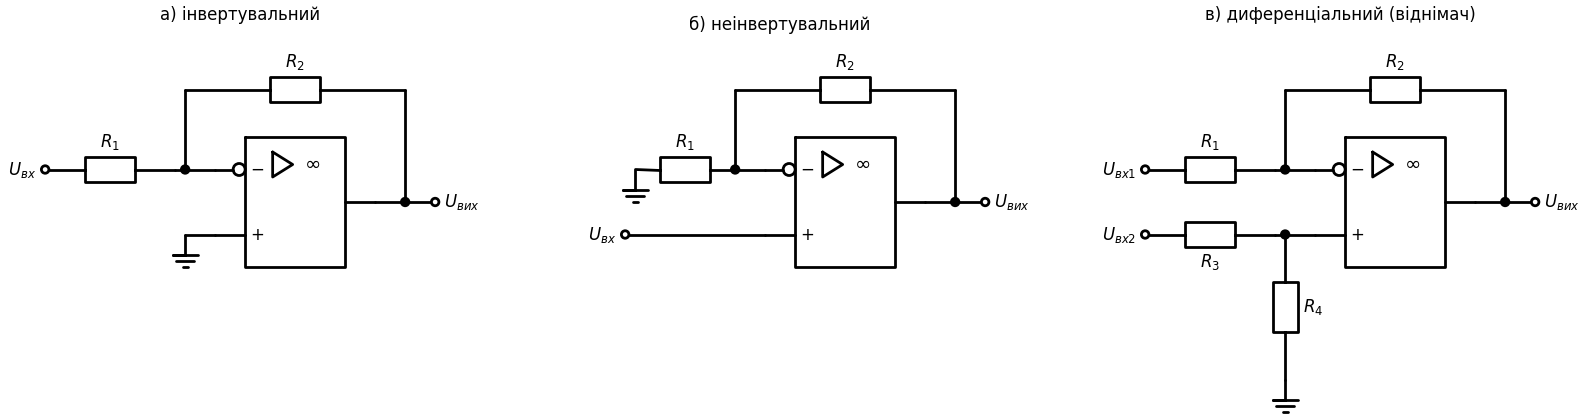

In [3]:
# а) інвертувальний; б) неінвертувальний; в) диференціальний підсилювач на ОП
if SCHEMDRAW_AVAILABLE:
    with schemdraw.Drawing(fontsize=12, unit=2) as d:
        W = lambda p1, p2: elm.Line().at(p1).to(p2)
        # а) інвертувальний: in1 у точці (3.4, 2.0)
        d += elm.Label().at((3.8, 5.0)).label('а) інвертувальний')
        d += elm.Dot(open=True).at((0, 2)).label('$U_{вх}$', loc='left')
        d += elm.Resistor().at((0, 2)).to((2.6, 2)).label('$R_1$')
        d += W((2.6, 2), (3.4, 2)); d += elm.Dot().at((2.8, 2))
        d += (o := OpAmp().at((3.4, 2)).anchor('in1'))
        d += W((2.8, 2), (2.8, 3.6)); d += elm.Resistor().at((2.8, 3.6)).to((7.2, 3.6)).label('$R_2$')
        d += W((7.2, 3.6), (7.2, o.out[1])); d += elm.Dot().at((7.2, o.out[1]))
        d += W(o.out, (7.8, o.out[1])); d += elm.Dot(open=True).at((7.8, o.out[1])).label('$U_{вих}$', loc='right')
        d += W(o.in2, (2.8, o.in2[1])); d += elm.Ground().at((2.8, o.in2[1]))
        # б) неінвертувальний
        ox = 11
        d += elm.Label().at((ox + 3.8, 5.0)).label('б) неінвертувальний')
        d += (o := OpAmp().at((ox + 3.4, 2)).anchor('in1'))
        d += elm.Dot(open=True).at((ox + 0.6, o.in2[1])).label('$U_{вх}$', loc='left'); d += W((ox + 0.6, o.in2[1]), o.in2)
        d += W((ox + 2.8, 2), (ox + 3.4, 2)); d += elm.Dot().at((ox + 2.8, 2))
        d += elm.Resistor().at((ox + 2.8, 2)).to((ox + 0.8, 2)).label('$R_1$', loc='top'); d += elm.Ground().at((ox + 0.8, 2))
        d += W((ox + 2.8, 2), (ox + 2.8, 3.6)); d += elm.Resistor().at((ox + 2.8, 3.6)).to((ox + 7.2, 3.6)).label('$R_2$')
        d += W((ox + 7.2, 3.6), (ox + 7.2, o.out[1])); d += elm.Dot().at((ox + 7.2, o.out[1]))
        d += W(o.out, (ox + 7.8, o.out[1])); d += elm.Dot(open=True).at((ox + 7.8, o.out[1])).label('$U_{вих}$', loc='right')
        # в) диференціальний
        ox = 22
        d += elm.Label().at((ox + 3.8, 5.0)).label('в) диференціальний (віднімач)')
        d += (o := OpAmp().at((ox + 3.4, 2)).anchor('in1'))
        d += elm.Dot(open=True).at((ox, 2)).label('$U_{вх1}$', loc='left')
        d += elm.Resistor().at((ox, 2)).to((ox + 2.6, 2)).label('$R_1$'); d += W((ox + 2.6, 2), (ox + 3.4, 2)); d += elm.Dot().at((ox + 2.8, 2))
        d += W((ox + 2.8, 2), (ox + 2.8, 3.6)); d += elm.Resistor().at((ox + 2.8, 3.6)).to((ox + 7.2, 3.6)).label('$R_2$')
        d += W((ox + 7.2, 3.6), (ox + 7.2, o.out[1])); d += elm.Dot().at((ox + 7.2, o.out[1]))
        d += W(o.out, (ox + 7.8, o.out[1])); d += elm.Dot(open=True).at((ox + 7.8, o.out[1])).label('$U_{вих}$', loc='right')
        d += elm.Dot(open=True).at((ox, o.in2[1])).label('$U_{вх2}$', loc='left')
        d += elm.Resistor().at((ox, o.in2[1])).to((ox + 2.6, o.in2[1])).label('$R_3$', loc='bottom'); d += W((ox + 2.6, o.in2[1]), o.in2)
        d += elm.Dot().at((ox + 2.8, o.in2[1]))
        d += elm.Resistor().at((ox + 2.8, o.in2[1])).to((ox + 2.8, -2.2)).label('$R_4$', loc='bottom'); d += elm.Ground().at((ox + 2.8, -2.2))

---
### 🔬 Інтерактивно: АЧХ μA741 без ЗЗ і з ЗЗ: сталий добуток підсилення × смуга (PySpice) <a class="anchor" id="gbw-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Модель μA741 (±15 В). Чорна крива — АЧХ без ЗЗ (робоча точка задана через ланку ЗЗ лише за постійним струмом). Кольорові — неінвертувальний підсилювач з $K_{зз} = 1 + R_2/R_1$. Змінюйте $K_{зз}$: смуга $f_в \approx f_1/K_{зз}$, а АЧХ з ЗЗ «впирається» в АЧХ ОП без ЗЗ.

</div>

In [4]:
# μA741: АЧХ без ЗЗ і для неінвертувального підсилювача з різним K_зз
def gbw(K_cl=100.0):
    c = opamp_circuit('open loop')
    c.SinusoidalVoltageSource('in', 'p', c.gnd, amplitude=1e-6, ac_magnitude=1)
    add_opamp(c, 1, 'p', 'm', 'out'); c.R('f', 'out', 'm', 1e5); c.C('f', 'm', c.gnd, 1e6)   # ЗЗ лише за постійним струмом
    f, v = ac(c, 0.1, 1e7, 20); K = np.abs(v['out'])
    fig, ax = plt.subplots(figsize=(9, 4.3))
    ax.semilogx(f, db(K), 'k', label=f'без ЗЗ: K₀ = {db(K[0]):.0f} дБ')
    for kc, col in ((K_cl, '#F44336'), (1.0, '#4CAF50')):
        c = opamp_circuit('noninv')
        c.SinusoidalVoltageSource('in', 'p', c.gnd, amplitude=1e-3, ac_magnitude=1)
        add_opamp(c, 1, 'p', 'm', 'out')
        if kc > 1:
            c.R(1, 'm', c.gnd, 1e3); c.R(2, 'out', 'm', (kc - 1) * 1e3)
        else:
            c.R(2, 'out', 'm', 1)
        f2, v2 = ac(c, 0.1, 1e7, 20); g = np.abs(v2['out'])
        fv = f2[np.argmax(g < g[0] / np.sqrt(2))]
        ax.semilogx(f2, db(g), color=col, label=f'K_зз = {kc:.0f}: fв = {fv/1e3:.1f} кГц,  K·fв = {kc*fv/1e6:.2f} МГц')
    ax.set_xlabel('Частота, Гц'); ax.set_ylabel('K, дБ'); ax.set_ylim(-20, 110); ax.legend(fontsize=9)
    ax.set_title('μA741: підсилення × смуга = f₁ ≈ 1 МГц')
    plt.tight_layout(); plt.show()

interact(gbw, K_cl=widgets.FloatLogSlider(base=10, min=0.5, max=3.5, step=0.1, value=100, description='K_зз'));

interactive(children=(FloatLogSlider(value=100.0, description='K_зз', max=3.5, min=0.5), Output()), _dom_class…

---
### 🔬 Інтерактивно: інвертувальний і неінвертувальний підсилювачі: насичення і швидкість наростання (PySpice) <a class="anchor" id="inv-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Часові діаграми для μA741 (±15 В). Збільшуйте амплітуду — вихід обмежується на рівні ≈ ±13 В. Збільшуйте частоту при великій амплітуді — синусоїда перетворюється на трикутник: вихід не встигає змінюватися швидше за $V_U \approx 0{,}5$ В/мкс. Під графіком — оцінка смуги повної потужності $f_{max} = V_U/(2\pi U_m)$.

</div>

In [5]:
# Інвертувальний / неінвертувальний підсилювач на μA741: перехідний аналіз
def amp_tran(kind='інвертувальний', R2_k=47.0, Uin=0.5, f_kHz=1.0):
    c = opamp_circuit(kind)
    c.SinusoidalVoltageSource('in', 'src', c.gnd, amplitude=Uin, frequency=f_kHz * 1e3)
    R1 = 10e3
    if kind == 'інвертувальний':
        c.R(1, 'src', 'm', R1); c.R(2, 'm', 'out', R2_k * 1e3); c.R(3, 'p', c.gnd, R1 * R2_k * 1e3 / (R1 + R2_k * 1e3))
        add_opamp(c, 1, 'p', 'm', 'out'); K = -R2_k * 1e3 / R1
    else:
        c.R(1, 'm', c.gnd, R1); c.R(2, 'm', 'out', R2_k * 1e3); c.R(3, 'src', 'p', 1)
        add_opamp(c, 1, 'p', 'm', 'out'); K = 1 + R2_k * 1e3 / R1
    T = 1 / (f_kHz * 1e3)
    t, v = tran(c, T / 400, 6 * T, start=3 * T)
    tt = (t - t[0]) * 1e3
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.plot(tt, v['src'], 'k--', lw=1, label='$u_{вх}$'); ax.plot(tt, K * v['src'], color='#9E9E9E', lw=1, label='ідеальний $K u_{вх}$')
    ax.plot(tt, v['out'], color='#F44336', label='$u_{вих}$ (μA741)')
    ax.set_ylim(-16, 16); ax.set_xlabel('t, мс'); ax.set_ylabel('В'); ax.legend(loc='upper right', fontsize=9)
    ax.set_title(f'{kind}: K = {K:.1f}, f = {f_kHz:g} кГц')
    plt.tight_layout(); plt.show()
    Um = min(abs(K) * Uin, 13)
    print(f'Потрібна швидкість наростання 2πfU_m = {2*np.pi*f_kHz*1e3*Um/1e6:.2f} В/мкс (у μA741 ≈ 0,5 В/мкс);  '
          f'смуга за малим сигналом f₁/(1+R2/R1) = {1e6/(1+R2_k*1e3/R1)/1e3:.1f} кГц')

interact(amp_tran,
         kind=widgets.ToggleButtons(options=['інвертувальний', 'неінвертувальний'], description='Схема'),
         R2_k=widgets.FloatSlider(min=10, max=200, step=1, value=47, description='R2 (кОм)'),
         Uin=widgets.FloatSlider(min=0.05, max=5, step=0.05, value=0.5, description='Uвх (В)'),
         f_kHz=widgets.FloatLogSlider(base=10, min=-1, max=2, step=0.1, value=1, description='f (кГц)'));

interactive(children=(ToggleButtons(description='Схема', options=('інвертувальний', 'неінвертувальний'), value…

### ⚠️ Типова помилка

<div style="background-color: #fef2f2; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #dc2626; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

**Правило «віртуального КЗ» справедливе лише при негативному ЗЗ і без насичення.** Якщо вихід ОП обмежився (насичення) або ЗЗ позитивний (компаратор, тригер Шмітта — тема 9), напруги на входах **не рівні**. Також: неінвертувальний вхід не можна залишати «у повітрі» — без кола для протікання вхідного струму ОП зміщеннями «заганяє» вихід у насичення.

</div>

---

## Повторювачі напруги на ОП <a class="anchor" id="followers"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 2.8</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Пояснювати роботу повторювача напруги на ОП і його переваги над транзисторними повторювачами
> - Знати різновиди повторювачів: з підсиленням, інвертувальний, з вольтодобавкою, з підсиленням струму
> - Визначати області застосування повторювачів

</div>

**Повторювач напруги** — неінвертувальний підсилювач зі 100 % НЗЗ ($R_1 = \infty$, $R_2 = 0$): вихід з'єднано з інвертувальним входом, сигнал подається на неінвертувальний.
$$K_u = \frac{K_0}{1 + K_0} \approx 1 - \frac{1}{K_0},\qquad R_{вх} \approx R_{вх.д}(1 + K_0)\parallel R_{вх.сф},\qquad R_{вих} \approx \frac{R_{вих.ОП}}{1 + K_0},\qquad f_в = f_1 .$$
Порівняно з емітерним повторювачем ($K_u \approx 0{,}95\ldots0{,}99$, зсув $U_{бе} \approx 0{,}65$ В) повторювач на ОП має $K_u = 1$ з похибкою $10^{-5}$, **немає зсуву рівня** (лише $U_{зм}$ — мілівольти), вхідний опір — гігаоми (у ОП з ПТ-входом — терраоми), вихідний — міліоми.

**Різновиди:**
- **повторювач з підсиленням** — неінвертувальний підсилювач з $K = 1 + R_2/R_1$;
- **інвертувальний повторювач (інвертор)** — інвертувальний підсилювач з $R_1 = R_2$: $K = -1$ (але $R_{вх} = R_1$);
- **повторювач змінного сигналу з вольтодобавкою** — резистор зміщення неінвертувального входу живиться від виходу через конденсатор, і його ефективний опір зростає в $K_0$ разів;
- **повторювач з підсиленням струму** — у петлю ЗЗ вмикають двотактний емітерний повторювач (VT1, VT2); НЗЗ усуває «сходинку» (перехідні спотворення) класу B;
- **повторювач для ємнісного навантаження** — з ізоляційним резистором $R_{із}$ (10…100 Ом) на виході і корекційним колом, бо ємність навантаження разом з $R_{вих}$ додає полюс у петлю ЗЗ і зменшує запас стійкості.

**Застосування:** буфер між високоомним джерелом (датчик, подільник напруги, ланка RC-фільтра) і навантаженням; буфер опорної напруги для АЦП/ЦАП; розв'язувальний каскад між ланками активних фільтрів; «віртуальна земля» (половина напруги живлення) в однополярних схемах; повторювач для екранування (guard) вхідних кіл чутливих вимірювань; драйвер кабелю.

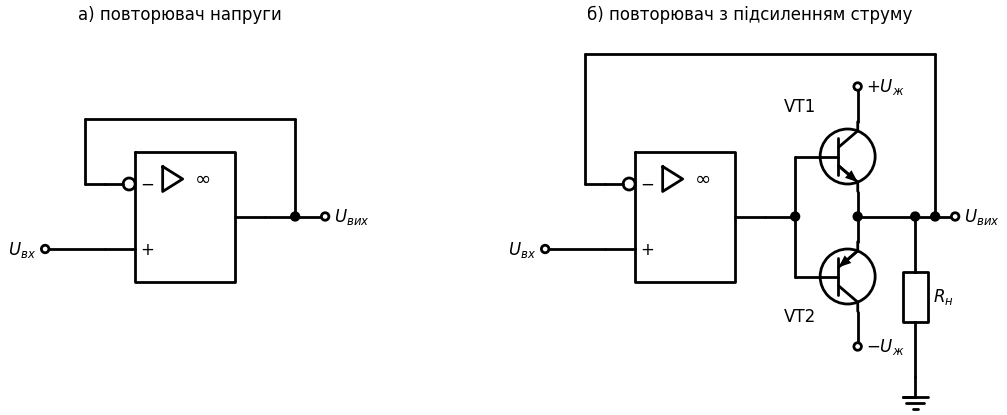

In [6]:
# а) повторювач; б) повторювач з підсиленням струму (двотактний повторювач у петлі ЗЗ)
if SCHEMDRAW_AVAILABLE:
    with schemdraw.Drawing(fontsize=12, unit=2) as d:
        W = lambda p1, p2: elm.Line().at(p1).to(p2)
        d += elm.Label().at((2.6, 5.3)).label('а) повторювач напруги')
        d += (o := OpAmp().at((1.2, 2)).anchor('in1'))
        d += elm.Dot(open=True).at((0, o.in2[1])).label('$U_{вх}$', loc='left'); d += W((0, o.in2[1]), o.in2)
        d += W((0.8, 2), (1.2, 2)); d += W((0.8, 2), (0.8, 3.3)); d += W((0.8, 3.3), (5.0, 3.3)); d += W((5.0, 3.3), (5.0, o.out[1]))
        d += W(o.out, (5.6, o.out[1])); d += elm.Dot().at((5.0, o.out[1])); d += elm.Dot(open=True).at((5.6, o.out[1])).label('$U_{вих}$', loc='right')
        # б) з підсиленням струму
        ox = 10
        d += elm.Label().at((ox + 4.0, 5.3)).label('б) повторювач з підсиленням струму')
        d += (o := OpAmp().at((ox + 1.2, 2)).anchor('in1'))
        d += elm.Dot(open=True).at((ox, o.in2[1])).label('$U_{вх}$', loc='left'); d += W((ox, o.in2[1]), o.in2)
        y = o.out[1]
        d += W(o.out, (ox + 5.0, y)); d += elm.Dot().at((ox + 5.0, y))
        d += W((ox + 5.0, y), (ox + 5.0, y + 1.2)); d += W((ox + 5.0, y + 1.2), (ox + 5.5, y + 1.2))
        d += W((ox + 5.0, y), (ox + 5.0, y - 1.2)); d += W((ox + 5.0, y - 1.2), (ox + 5.5, y - 1.2))
        d += elm.BjtNpn(circle=True).theta(0).at((ox + 5.5, y + 1.2)).anchor('base'); d += elm.Label().at((ox + 5.0, y + 2.1)).label('VT1')
        d += elm.BjtPnp(circle=True).theta(0).at((ox + 5.5, y - 1.2)).anchor('base'); d += elm.Label().at((ox + 5.0, y - 2.1)).label('VT2')
        d += W((ox + 6.25, y + 1.9), (ox + 6.25, y + 2.6)); d += elm.Dot(open=True).at((ox + 6.25, y + 2.6)).label('$+U_ж$', loc='right')
        d += W((ox + 6.25, y - 1.9), (ox + 6.25, y - 2.6)); d += elm.Dot(open=True).at((ox + 6.25, y - 2.6)).label('$-U_ж$', loc='right')
        d += W((ox + 6.25, y + 0.5), (ox + 6.25, y - 0.5)); d += elm.Dot().at((ox + 6.25, y))
        d += W((ox + 6.25, y), (ox + 8.2, y)); d += elm.Dot(open=True).at((ox + 8.2, y)).label('$U_{вих}$', loc='right')
        d += elm.Dot().at((ox + 7.4, y)); d += elm.Resistor().at((ox + 7.4, y)).to((ox + 7.4, y - 3.2)).label('$R_н$', loc='bottom'); d += elm.Ground().at((ox + 7.4, y - 3.2))
        d += W((ox + 0.8, 2), (ox + 1.2, 2)); d += W((ox + 0.8, 2), (ox + 0.8, 4.6)); d += W((ox + 0.8, 4.6), (ox + 7.8, 4.6)); d += W((ox + 7.8, 4.6), (ox + 7.8, y)); d += elm.Dot().at((ox + 7.8, y))

---
### 🔬 Інтерактивно: навіщо потрібен повторювач: навантаження подільника і двотактний вихід (PySpice) <a class="anchor" id="follower-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Ліворуч: подільник напруги 10 В з резисторами 10 кОм / 10 кОм навантажено опором $R_н$ — безпосередньо і через повторювач на μA741. Без буфера напруга «просідає», з буфером — ні (поки струм не перевищує можливостей ОП). Праворуч: двотактний повторювач (клас B) без ЗЗ дає «сходинку» біля нуля (перехідні спотворення), а охоплений петлею ЗЗ ОП — практично ні.

</div>

In [7]:
# Повторювач на ОП: буферизація подільника та усунення «сходинки» двотактного каскаду
def followers(Rl_k=2.0):
    vals = {}
    for buf in (False, True):
        c = opamp_circuit('divider')
        c.V('s', 'src', c.gnd, 10); c.R(1, 'src', 'mid', 10e3); c.R(2, 'mid', c.gnd, 10e3)
        if buf:
            add_opamp(c, 1, 'mid', 'out', 'out'); c.R('L', 'out', c.gnd, Rl_k * 1e3)
        else:
            c.R('L', 'mid', c.gnd, Rl_k * 1e3)
        op = c.simulator(temperature=25, nominal_temperature=25).operating_point()
        vals[buf] = float(np.array(op['out' if buf else 'mid'])[0])
    res = {}
    for loop in (False, True):
        c = opamp_circuit('push-pull')
        c.include(spice_model('2n3904.lib')); c.model('QP', 'PNP', BF=150, IS=1e-14, VAF=60)
        c.SinusoidalVoltageSource('in', 'src', c.gnd, amplitude=2, frequency=1e3)
        if loop:
            add_opamp(c, 1, 'src', 'out', 'drv')
        else:
            c.R('d', 'src', 'drv', 1)
        c.BJT(1, 'vcc', 'drv', 'out', model='Q2N3904'); c.BJT(2, 'vee', 'drv', 'out', model='QP')
        c.R('L', 'out', c.gnd, 100)
        t, v = tran(c, 1e-6, 3e-3, start=1e-3); res[loop] = (t, v)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
    a1.bar(['без повторювача', 'з повторювачем'], [vals[False], vals[True]], color=['#9E9E9E', '#4CAF50'])
    a1.axhline(5, color='k', ls='--', lw=1, label='без навантаження: 5 В'); a1.set_ylim(0, 6); a1.legend()
    for i, k in enumerate((False, True)):
        a1.text(i, vals[k], f'{vals[k]:.3f} В', ha='center', va='bottom')
    a1.set_title(f'Подільник 10 кОм/10 кОм, $R_н$ = {Rl_k:g} кОм'); a1.set_ylabel('$U_{вих}$, В')
    for loop, col, lab in ((False, '#2196F3', 'без ЗЗ («сходинка»)'), (True, '#F44336', 'у петлі ЗЗ ОП')):
        t, v = res[loop]; a2.plot((t - t[0]) * 1e3, v['out'], color=col, label=lab)
    a2.plot((t - t[0]) * 1e3, v['src'], 'k--', lw=1, label='$u_{вх}$')
    a2.set_xlabel('t, мс'); a2.set_ylabel('В'); a2.legend(fontsize=9); a2.set_title('Двотактний повторювач (клас B), $R_н$ = 100 Ом')
    plt.tight_layout(); plt.show()

interact(followers, Rl_k=widgets.FloatLogSlider(base=10, min=-0.5, max=2, step=0.1, value=2, description='Rн (кОм)'));

interactive(children=(FloatLogSlider(value=2.0, description='Rн (кОм)', max=2.0, min=-0.5), Output()), _dom_cl…

---

## Суматори сигналів на ОП <a class="anchor" id="summers"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 2.9</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Виводити вихідну напругу інвертувального і неінвертувального суматорів
> - Синтезувати алгебраїчний суматор із заданими ваговими коефіцієнтами
> - Наводити приклади застосування суматорів (мікшер, ЦАП, зсув рівня)

</div>

### Інвертувальний суматор

Кілька вхідних резисторів $R_1\ldots R_n$ під'єднано до «віртуальної землі» інвертувального входу. Струми $U_i/R_i$ складаються у вузлі і повністю протікають через $R_{зз}$:
$$U_{вих} = -R_{зз}\sum_{i=1}^{n}\frac{U_i}{R_i} = -\left(\frac{R_{зз}}{R_1}U_1 + \frac{R_{зз}}{R_2}U_2 + \dots\right).$$
Головна перевага — **входи не взаємодіють**: кожне джерело навантажене лише своїм $R_i$ на віртуальну землю, тому вагові коефіцієнти незалежні й легко регулюються. Вхідний опір $i$-го входу — $R_i$. Смуга: $f_в = f_1/(1 + R_{зз}/(R_1\parallel R_2\parallel\ldots))$ — коефіцієнт «шумового підсилення» зростає з кількістю входів.

### Неінвертувальний суматор

Вхідні напруги через резистори $R_i$ подаються на неінвертувальний вхід (вузол «усереднення»), а ОП працює як неінвертувальний підсилювач з $K = 1 + R_{зз}/R_0$. При однакових $R_i = R$:
$$U_+ = \frac{1}{n}\sum U_i,\qquad U_{вих} = \left(1 + \frac{R_{зз}}{R_0}\right)\frac{1}{n}\sum_{i=1}^n U_i .$$
У загальному випадку $U_+ = \sum (U_i/R_i)\big/\sum(1/R_i)$ — вагові коефіцієнти **залежать один від одного** (зміна одного $R_i$ змінює всі ваги), а джерела взаємодіють через спільний вузол. Перевага — великий вхідний опір і відсутність інверсії.

### Алгебраїчний суматор (суматор-віднімач)

Поєднання обох схем: сигнали з вагами «+» подають на неінвертувальний вхід, з вагами «−» — на інвертувальний. Для
$$U_{вих} = \sum_{i}a_iU_i^{+} - \sum_{j}b_jU_j^{-}$$
вибирають $R_j^- = R_{зз}/b_j$, а коло неінвертувального входу розраховують так, щоб сума коефіцієнтів $\sum a_i$ відповідала $1 + R_{зз}/(R_1^-\parallel\ldots)$ (за потреби додають резистор з неінвертувального входу на землю). Частковий випадок — диференціальний підсилювач.

**Застосування:** звукові мікшери, формування сигналів із кількох джерел (сигнал + постійне зміщення = **зсув рівня**), ЦАП з ваговими резисторами ($R_i = R\cdot2^i$), аналогові обчислювальні схеми (розв'язання диференціальних рівнянь), формування сигналів керування в регуляторах (ПІД: сума пропорційної, інтегральної і диференціальної складових), компенсація зміщення нуля датчиків.

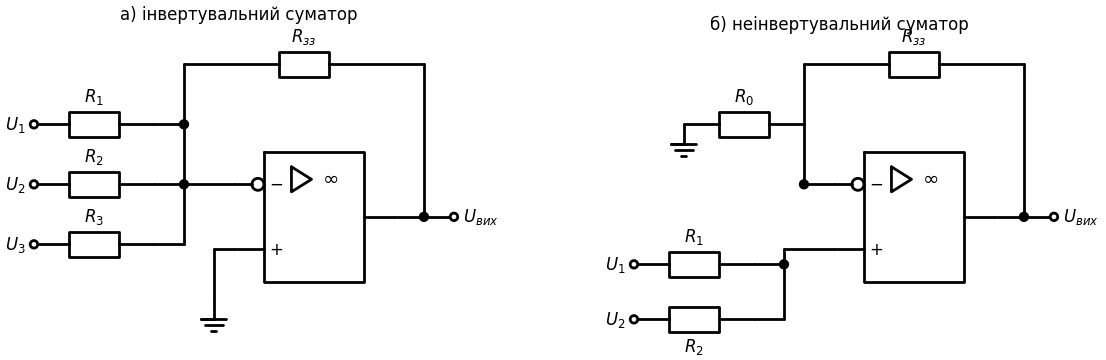

In [8]:
# а) інвертувальний суматор на три входи; б) неінвертувальний суматор
if SCHEMDRAW_AVAILABLE:
    with schemdraw.Drawing(fontsize=12, unit=2) as d:
        W = lambda p1, p2: elm.Line().at(p1).to(p2)
        d += elm.Label().at((4.0, 5.3)).label('а) інвертувальний суматор')
        d += (o := OpAmp().at((4.0, 2)).anchor('in1'))
        for k, y in enumerate((3.2, 2.0, 0.8), 1):
            d += elm.Dot(open=True).at((0, y)).label(f'$U_{k}$', loc='left')
            d += elm.Resistor().at((0, y)).to((2.4, y)).label(f'$R_{k}$')
            d += W((2.4, y), (3.0, y))
        d += W((3.0, 3.2), (3.0, 0.8)); d += elm.Dot().at((3.0, 2.0)); d += W((3.0, 2.0), (4.0, 2.0))
        d += elm.Dot().at((3.0, 3.2)); d += W((3.0, 3.2), (3.0, 4.4)); d += elm.Resistor().at((3.0, 4.4)).to((7.8, 4.4)).label('$R_{зз}$')
        d += W((7.8, 4.4), (7.8, o.out[1])); d += elm.Dot().at((7.8, o.out[1]))
        d += W(o.out, (8.4, o.out[1])); d += elm.Dot(open=True).at((8.4, o.out[1])).label('$U_{вих}$', loc='right')
        d += W(o.in2, (3.6, o.in2[1])); d += W((3.6, o.in2[1]), (3.6, -0.3)); d += elm.Ground().at((3.6, -0.3))
        # б) неінвертувальний
        ox = 12
        d += elm.Label().at((ox + 4.0, 5.3)).label('б) неінвертувальний суматор')
        d += (o := OpAmp().at((ox + 4.0, 2)).anchor('in1'))
        for k, y in enumerate((0.4, -0.7), 1):
            d += elm.Dot(open=True).at((ox, y)).label(f'$U_{k}$', loc='left')
            d += elm.Resistor().at((ox, y)).to((ox + 2.4, y)).label(f'$R_{k}$', loc='bottom' if k == 2 else 'top')
            d += W((ox + 2.4, y), (ox + 3.0, y))
        d += W((ox + 3.0, 0.4), (ox + 3.0, -0.7)); d += W((ox + 3.0, 0.4), (ox + 3.0, o.in2[1])); d += W((ox + 3.0, o.in2[1]), o.in2)
        d += elm.Dot().at((ox + 3.0, 0.4))
        d += W((ox + 3.4, 2.0), (ox + 4.0, 2.0)); d += elm.Dot().at((ox + 3.4, 2.0))
        d += W((ox + 3.4, 2.0), (ox + 3.4, 3.2)); d += elm.Resistor().at((ox + 3.4, 3.2)).to((ox + 1.0, 3.2)).label('$R_0$', loc='top'); d += elm.Ground().at((ox + 1.0, 3.2))
        d += W((ox + 3.4, 3.2), (ox + 3.4, 4.4)); d += elm.Resistor().at((ox + 3.4, 4.4)).to((ox + 7.8, 4.4)).label('$R_{зз}$')
        d += W((ox + 7.8, 4.4), (ox + 7.8, o.out[1])); d += elm.Dot().at((ox + 7.8, o.out[1]))
        d += W(o.out, (ox + 8.4, o.out[1])); d += elm.Dot(open=True).at((ox + 8.4, o.out[1])).label('$U_{вих}$', loc='right')

---
### 🔬 Інтерактивно: інвертувальний і алгебраїчний суматори (PySpice) <a class="anchor" id="summer-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Три сигнали: синус 1 кГц ($U_1$), прямокутні імпульси 200 Гц ($U_2$) і постійна напруга $U_3$ подано на інвертувальний суматор на μA741 з $R_{зз} = 10$ кОм. Змінюйте вхідні резистори — кожен ваговий коефіцієнт $-R_{зз}/R_i$ змінюється незалежно від інших. Пунктир — теоретичний результат $-\sum (R_{зз}/R_i)U_i$.

</div>

In [9]:
# Інвертувальний суматор на μA741: три входи з незалежними ваговими коефіцієнтами
def summer(R1_k=10.0, R2_k=20.0, R3_k=10.0, U3=1.0):
    c = opamp_circuit('summer')
    c.SinusoidalVoltageSource('1', 'u1', c.gnd, amplitude=1.0, frequency=1e3)
    c.PulseVoltageSource('2', 'u2', c.gnd, initial_value=-1, pulsed_value=1, pulse_width=2.5e-3, period=5e-3, rise_time=1e-6, fall_time=1e-6)
    c.V('3', 'u3', c.gnd, U3)
    Rf = 10e3
    c.R(1, 'u1', 'm', R1_k * 1e3); c.R(2, 'u2', 'm', R2_k * 1e3); c.R(3, 'u3', 'm', R3_k * 1e3)
    c.R('f', 'm', 'out', Rf); add_opamp(c, 1, c.gnd, 'm', 'out')
    t, v = tran(c, 5e-6, 10e-3)
    ideal = -(Rf / (R1_k * 1e3) * v['u1'] + Rf / (R2_k * 1e3) * v['u2'] + Rf / (R3_k * 1e3) * U3)
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
    a1.plot(t * 1e3, v['u1'], color='#2196F3', label='$U_1$'); a1.plot(t * 1e3, v['u2'], color='#4CAF50', label='$U_2$')
    a1.axhline(U3, color='#FF9800', label='$U_3$'); a1.legend(loc='upper left', bbox_to_anchor=(1.01, 1)); a1.set_ylabel('В'); a1.set_title('Вхідні сигнали')
    a2.plot(t * 1e3, v['out'], color='#F44336', label='$U_{вих}$ (μA741)'); a2.plot(t * 1e3, ideal, 'k--', lw=1, label='теорія')
    a2.set_xlabel('t, мс'); a2.set_ylabel('В'); a2.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
    a2.set_title(f'$U_{{вих}} = -({Rf/R1_k/1e3:.2f}U_1 + {Rf/R2_k/1e3:.2f}U_2 + {Rf/R3_k/1e3:.2f}U_3)$')
    plt.tight_layout(); plt.show()

interact(summer,
         R1_k=widgets.FloatSlider(min=2, max=50, step=1, value=10, description='R1 (кОм)'),
         R2_k=widgets.FloatSlider(min=2, max=50, step=1, value=20, description='R2 (кОм)'),
         R3_k=widgets.FloatSlider(min=2, max=50, step=1, value=10, description='R3 (кОм)'),
         U3=widgets.FloatSlider(min=-3, max=3, step=0.1, value=1, description='U3 (В)'));

interactive(children=(FloatSlider(value=10.0, description='R1 (кОм)', max=50.0, min=2.0, step=1.0), FloatSlide…

### 💡 Суматор як ЦАП з ваговими резисторами

<div style="background-color: #f0f9ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #0284c7; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Якщо цифрові розряди $b_i \in \{0, 1\}$ керують ключами, що подають опорну напругу $U_{оп}$ на резистори $R, 2R, 4R, \ldots, 2^{n-1}R$ інвертувального суматора з $R_{зз} = R/2$, то
$$U_{вих} = -U_{оп}\left(\frac{b_{n-1}}{2} + \frac{b_{n-2}}{4} + \ldots + \frac{b_0}{2^n}\right) = -U_{оп}\frac{N}{2^n}.$$
Недолік — великий розкид номіналів при $n > 8$; тому на практиці використовують матрицю R–2R (тільки два номінали), яка також працює на віртуальну землю інвертувального суматора.

</div>

### ⚠️ Типова помилка

<div style="background-color: #fef2f2; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #dc2626; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

**У неінвертувальному суматорі ваги «зв'язані».** Якщо змінити один вхідний резистор, зміняться коефіцієнти *всіх* входів, бо вузол неінвертувального входу — звичайний подільник, а не віртуальна земля. Крім того, джерела сигналів навантажують одне одного. Якщо потрібно незалежно регулювати рівні (мікшер), використовують інвертувальний суматор, а за потреби — ще один інвертор після нього.

</div>

---
### ⚡ Практичне застосування: ОП у схемах загального призначення

<div style="background-color: #fffbeb; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #f59e0b; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

| Задача | Схема на ОП | Ключове співвідношення |
|---|---|---|
| Підсилення сигналу датчика | неінвертувальний підсилювач | $K = 1 + R_2/R_1$, великий $R_{вх}$ |
| Зміна полярності, масштабування | інвертувальний підсилювач | $K = -R_2/R_1$ |
| Буфер опорної напруги АЦП | повторювач | $K = 1$, малий $R_{вих}$ |
| «Віртуальна земля» при однополярному живленні | повторювач від подільника $U_ж/2$ | |
| Звуковий мікшер | інвертувальний суматор | $U_{вих} = -\sum (R_{зз}/R_i)U_i$ |
| Зсув рівня сигналу (АЦП 0…3,3 В з біполярного сигналу) | суматор сигналу і зміщення | $U_{вих} = aU_{вх} + U_0$ |
| ЦАП | суматор з ваговими резисторами / R–2R | $U_{вих} = -U_{оп}N/2^n$ |
| Регулятор ПІД | суматор виходів П-, І-, Д-ланок | тема 8 |

</div>

---
### ✅ Питання для самоперевірки: ОП, повторювачі, суматори

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 1.</b> Сформулюйте правила аналізу схем з ідеальним ОП. Коли вони справедливі?</summary>

> **Відповідь:** Напруги входів рівні (віртуальне КЗ), вхідні струми нульові. Справедливі лише при негативному ЗЗ і без насичення виходу.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 2.</b> Чому смуга неінвертувального підсилювача з $K = 100$ на μA741 лише 10 кГц?</summary>

> **Відповідь:** Скоригований ОП має сталий добуток підсилення × смуга $f_1 = 1$ МГц; $f_в = f_1/K = 10$ кГц.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 3.</b> Що таке швидкість наростання і як вона обмежує смугу?</summary>

> **Відповідь:** Максимальна швидкість зміни вихідної напруги $V_U$. Синус амплітудою $U_m$ не спотворюється, якщо $2\pi fU_m \le V_U$, тобто $f_{max} = V_U/(2\pi U_m)$.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 4.</b> Чим повторювач на ОП кращий за емітерний?</summary>

> **Відповідь:** $K = 1$ з похибкою $1/K_0$, немає зсуву $U_{бе}$, вхідний опір — гігаоми, вихідний — міліоми.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 5.</b> Чому входи інвертувального суматора не взаємодіють?</summary>

> **Відповідь:** Усі вхідні резистори під'єднано до віртуальної землі: напруга вузла дорівнює нулю, і струм кожного входу визначається лише $U_i/R_i$.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 6.</b> Навіщо в коло неінвертувального входу інвертувального підсилювача вмикають $R_3 = R_1\parallel R_2$?</summary>

> **Відповідь:** Щоб вхідні струми ОП створювали однакові падіння напруги на обох входах; похибка тоді визначається лише різницею вхідних струмів.

</details>

---
### 📝 Задачі для самостійного розв'язання: ОП, повторювачі, суматори


<div style="background-color: #fff1f2; padding: 12px 18px; border-radius: 10px; border-left: 4px solid #e11d48; box-shadow: 0 1px 3px rgba(0,0,0,0.08); margin: 10px 0;">

**Задача 1.** Розрахуйте інвертувальний підсилювач з $K = -20$ і $R_{вх} = 10$ кОм на ОП з $f_1 = 3$ МГц, $V_U = 13$ В/мкс. Яка його смуга і максимальна частота неспотвореного сигналу з амплітудою 10 В?

</div>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;">Відповідь і розв'язання</summary>

> $R_1 = 10$ кОм, $R_2 = 200$ кОм, $R_3 = 9{,}5$ кОм. $f_в = 3\,\text{МГц}/21 \approx 143$ кГц; $f_{max} = 13\cdot10^6/(2\pi\cdot10) \approx 207$ кГц — обмежує смуга малого сигналу (143 кГц).

</details>

<div style="background-color: #fff1f2; padding: 12px 18px; border-radius: 10px; border-left: 4px solid #e11d48; box-shadow: 0 1px 3px rgba(0,0,0,0.08); margin: 10px 0;">

**Задача 2.** Спроєктуйте схему $U_{вих} = -(2U_1 + 0{,}5U_2 + U_3)$ з $R_{зз} = 20$ кОм.

</div>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;">Відповідь і розв'язання</summary>

> Інвертувальний суматор: $R_1 = 10$ кОм, $R_2 = 40$ кОм, $R_3 = 20$ кОм.

</details>

<div style="background-color: #fff1f2; padding: 12px 18px; border-radius: 10px; border-left: 4px solid #e11d48; box-shadow: 0 1px 3px rgba(0,0,0,0.08); margin: 10px 0;">

**Задача 3.** Сигнал датчика $\pm1$ В треба перетворити в діапазон 0…3,3 В для АЦП. Запропонуйте схему.

</div>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;">Відповідь і розв'язання</summary>

> $U_{вих} = 1{,}65U_{вх} + 1{,}65$ В. Наприклад, інвертувальний суматор з вагами $-1{,}65$ для $U_{вх}$ і $-1{,}65$ для опорної $-1$ В з наступним інвертором, або неінвертувальна схема з подільником $U_{оп}$ на неінвертувальному вході.

</details>

---

### 📌 Підсумок теми <a class="anchor" id="topic-summary"></a>

<div style="background-color: #f0fdf4; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #16a34a; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

| Схема | Співвідношення |
|---|---|
| Правила ідеального ОП (з НЗЗ) | $U_+ = U_-$, $I_+ = I_- = 0$ |
| Інвертувальний підсилювач | $K = -R_2/R_1$, $R_{вх} = R_1$ |
| Неінвертувальний підсилювач | $K = 1 + R_2/R_1$, $R_{вх} \to\infty$ |
| Диференціальний | $U_{вих} = \frac{R_2}{R_1}(U_2 - U_1)$ при $R_3/R_4 = R_1/R_2$ |
| Повторювач | $K = 1$, $R_{вих} = R_{вих.ОП}/K_0$ |
| Інвертувальний суматор | $U_{вих} = -R_{зз}\sum U_i/R_i$ |
| Неінвертувальний суматор | $U_{вих} = (1 + R_{зз}/R_0)\,\overline{U}$ (при рівних $R_i$) |
| Динамічні обмеження | $f_в = f_1/K_{зз}$, $f_{max} = V_U/(2\pi U_m)$ |

**Головні висновки.** ОП з глибоким НЗЗ — універсальний блок, властивості якого задаються пасивними елементами кола ЗЗ. Два правила ідеального ОП дозволяють швидко розрахувати будь-яку схему; реальні обмеження — сталий добуток підсилення × смуга, швидкість наростання, діапазон вихідних напруг, зміщення нуля і вхідні струми.

</div>

---

## 📚 Рекомендована література та ресурси <a class="anchor" id="references"></a>

**Основна література**

1. Гусев В. Г., Гусев Ю. М. Електроніка і мікропроцесорна техніка. — К.: Вища школа (укр. пер.).
2. Опадчий Ю. Ф., Глудкин О. П., Гуров А. И. Аналоговая и цифровая электроника. — М.: Горячая линия – Телеком, 2000.
3. Титце У., Шенк К. Полупроводниковая схемотехника. — 12-е изд. — М.: ДМК Пресс, 2008.
4. Хоровиц П., Хилл У. Искусство схемотехники. — М.: Мир / Horowitz P., Hill W. The Art of Electronics. — 3rd ed. — Cambridge University Press, 2015.
5. Sedra A. S., Smith K. C. Microelectronic Circuits. — 8th ed. — Oxford University Press, 2020.

**Додаткова література**

6. Jung W. G. (ed.) Op Amp Applications Handbook. — Newnes / Analog Devices, 2005.
7. Mancini R. (ed.) Op Amps for Everyone. — Texas Instruments, 2002 (SLOD006).

**Програмні інструменти, що використовуються в конспекті**

- [PySpice](https://pyspice.fabrice-salvaire.fr/) + [ngspice](https://ngspice.sourceforge.io/) — схемотехнічне моделювання
- [SchemDraw](https://schemdraw.readthedocs.io/) — побудова електричних схем
- [SymPy](https://docs.sympy.org/) — символьні обчислення
- [NumPy](https://numpy.org/doc/) / [SciPy](https://docs.scipy.org/doc/scipy/) / [Matplotlib](https://matplotlib.org/) — чисельні розрахунки та графіки

---

<p style="text-align: center;">⬅️ [Тема 6. Джерела струму, струмові дзеркала, диференціальні каскади](Тема_06_Джерела_струму_та_диференціальні_каскади.ipynb) &nbsp;|&nbsp; [Тема 8. Інтегратори, диференціатори, вимірювальні підсилювачі, перетворювачі U→I та I→U](Тема_08_Лінійні_перетворювачі_на_ОП.ipynb) ➡️</p>

*Конспект підготовлено: Пахалюк Богдан Петрович, НУ "Чернігівська політехніка"*